### Sim2real, results

```run graph_dqn_sim2real.py ```

The step when training in simulation finishes is in the logs of each run. (in wandb)

In [1]:
import numpy as np
import pandas as pd
import gym
import matplotlib.pyplot as plt
%matplotlib inline 

In [2]:
run_names = ['laced-mountain-249', 'exalted-fog-250', 'jumping-wave-252']
# no of episodes in simulation
sim_eps = [685, 885, 632]

In [3]:
# the length of training curve in sim
steps_sim = min(sim_eps)
steps_real = 200

In [4]:
# load results
ep_scores_sync = np.zeros((len(run_names), steps_sim+steps_real))

for i in range(len(run_names)):
    name = './sim2real_results/wandb_export_' + run_names[i] + '.csv'
    sim_eps_cur = sim_eps[i]
    file = pd.read_csv(name)
    ep_scores_sync[i,:] = file.iloc[:, 1][sim_eps_cur-steps_sim+1:]    

In [5]:
# running average
def running_average(a, n):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n    

809

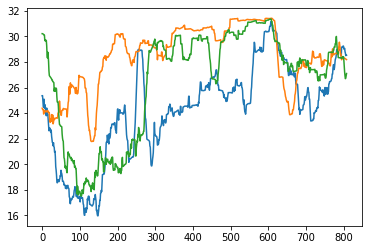

In [6]:
n = 24

ep_scores_sync_smooth = np.zeros((len(run_names), steps_sim+steps_real-n+1))

plt.figure()
for i in range(len(run_names)):
    ep_scores_sync_smooth[i, :] = running_average(ep_scores_sync[i,:], n)
    plt.plot(ep_scores_sync_smooth[i, :])
    
len_curve = steps_sim+steps_real-n+1
len_curve

In [8]:
train_scores_mean = np.mean(ep_scores_sync_smooth, axis=0)
train_scores_std = np.std(ep_scores_sync_smooth, axis=0)

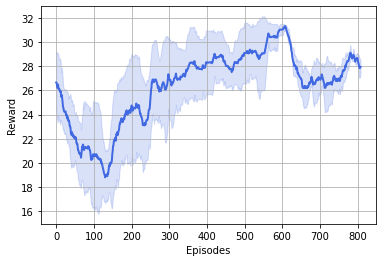

In [36]:
# Plot learning curve
_, axes = plt.subplots(1,1)
axes.grid()
axes.fill_between(
    np.array(range(len_curve)),
    train_scores_mean - train_scores_std,
    train_scores_mean + train_scores_std,
    alpha=0.2,
    color="royalblue",
)

axes.plot(
    np.array(range(len_curve)), train_scores_mean, linewidth=2, color="royalblue", label="Training score")

axes.set_xlabel("Episodes")
axes.set_ylabel("Reward")
# plt.savefig('sim2real_gap_training.pdf') 

### new figure: only keep training part

In [149]:
training_curve_len = steps_sim - n + 1

train_scores_mean = np.mean(ep_scores_sync_smooth, axis=0)[:training_curve_len]
train_scores_std = np.std(ep_scores_sync_smooth, axis=0)[:training_curve_len]

# load validation on sim
name = './sim2real_results/wandb_export_sim.csv'
validate_sim = pd.read_csv(name)

validate_sim.keys()

Index(['Step', 'genial-planet-263 - evaluation_ep_score',
       'genial-planet-263 - evaluation_ep_score__MIN',
       'genial-planet-263 - evaluation_ep_score__MAX',
       'happy-darkness-262 - evaluation_ep_score',
       'happy-darkness-262 - evaluation_ep_score__MIN',
       'happy-darkness-262 - evaluation_ep_score__MAX',
       'wandering-salad-261 - evaluation_ep_score',
       'wandering-salad-261 - evaluation_ep_score__MIN',
       'wandering-salad-261 - evaluation_ep_score__MAX'],
      dtype='object')

In [150]:
validate_sim_results = np.zeros((3,200))
validate_sim_results[0, :] = validate_sim['genial-planet-263 - evaluation_ep_score']
validate_sim_results[1, :] = validate_sim['happy-darkness-262 - evaluation_ep_score']
validate_sim_results[2, :] = validate_sim['wandering-salad-261 - evaluation_ep_score']

sim_scores_average = np.zeros((3, 200-n+1))
for i in range(3):
    sim_scores_average[i,:] = running_average(validate_sim_results[i,:], n)

sim_scores_mean = np.mean(sim_scores_average, axis=0)
sim_scores_std = np.std(sim_scores_average, axis=0)

In [151]:
# load validation on real
name = './sim2real_results/wandb_export_real.csv'
validate_real = pd.read_csv(name)

validate_real.keys()

Index(['Step', 'vocal-blaze-266 - evaluation_ep_score',
       'vocal-blaze-266 - evaluation_ep_score__MIN',
       'vocal-blaze-266 - evaluation_ep_score__MAX',
       'resilient-water-265 - evaluation_ep_score',
       'resilient-water-265 - evaluation_ep_score__MIN',
       'resilient-water-265 - evaluation_ep_score__MAX',
       'fancy-bee-264 - evaluation_ep_score',
       'fancy-bee-264 - evaluation_ep_score__MIN',
       'fancy-bee-264 - evaluation_ep_score__MAX'],
      dtype='object')

In [152]:
validate_real_results = np.zeros((3,200))
validate_real_results[0, :] = validate_real['vocal-blaze-266 - evaluation_ep_score']
validate_real_results[1, :] = validate_real['resilient-water-265 - evaluation_ep_score']
validate_real_results[2, :] = validate_real['fancy-bee-264 - evaluation_ep_score']

real_scores_average = np.zeros((3, 200-n+1))
for i in range(3):
    real_scores_average[i,:] = running_average(validate_real_results[i,:], n)
real_scores_mean = np.mean(real_scores_average, axis=0)
real_scores_std = np.std(real_scores_average, axis=0)

In [154]:
# Plot learning curve
train_scores_mean = np.append(train_scores_mean, sim_scores_mean[0])
train_scores_std = np.append(train_scores_std, sim_scores_std[0])


In [156]:

a = np.zeros(1)
a[0] = sim_scores_mean[-1]
real_scores_mean = np.concatenate([a, real_scores_mean])

a[0] = sim_scores_std[-1]
real_scores_std = np.concatenate([a, real_scores_std])

In [160]:
len(range(training_curve_len+200-n+2, training_curve_len+200-n-n+4))

0

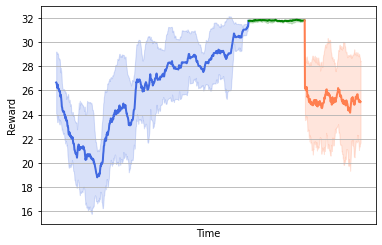

In [163]:

_, axes = plt.subplots(1,1)
axes.grid()
axes.fill_between(
    np.array(range(training_curve_len+1)),
    train_scores_mean - train_scores_std,
    train_scores_mean + train_scores_std,
    alpha=0.2,
    color="royalblue",
)

axes.plot(
    np.array(range(training_curve_len+1)), train_scores_mean, linewidth=2, color="royalblue", label="Training score")

axes.set_xlabel("Time")
axes.set_ylabel("Reward")

##
axes.fill_between(
    np.array(range(training_curve_len+1,training_curve_len+200-n+2)),
    sim_scores_mean - sim_scores_std,
    sim_scores_mean + sim_scores_std,
    alpha=0.2,
    color="g",
)

axes.plot(
    np.array(range(training_curve_len+1,training_curve_len+200-n+2)), sim_scores_mean, linewidth=2, color="g", label="Training score")

##
axes.fill_between(
    np.array(range(training_curve_len+200-n+2, training_curve_len+400-n-n+4)),
    real_scores_mean - real_scores_std,
    real_scores_mean + real_scores_std,
    alpha=0.2,
    color="coral",
)

axes.plot(
    np.array(range(training_curve_len+200-n+2, training_curve_len+400-n-n+4)), real_scores_mean, linewidth=2, color="coral", label="Training score")

# plt.axis('off')
plt.xticks([], [])

plt.savefig('sim2real_gap_training.pdf') 

### User distribution: sim vs real

In [10]:
env = gym.make("gym_graph_bbu_pooling:graph_bbu_pooling-v0")
_ = env.reset()

In [33]:
n_bins = 60

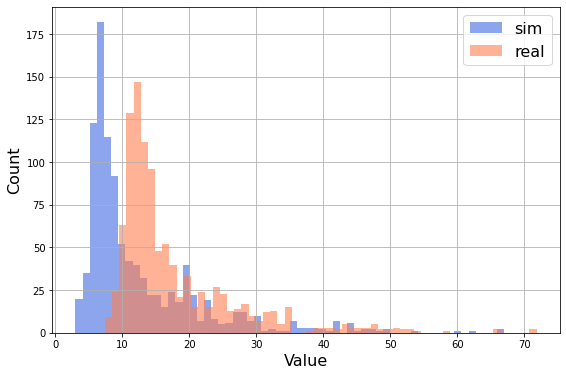

In [35]:
ue_dist_sim = []

for t in range(24):
    _, env.reset(t=t)
    feas = env.fea
    ue_dist_sim.extend(feas)
    
ue_dist_real = []

for t in range(24):
    _, env.reset(noise_fea=True, t=t)
    feas = env.fea
    ue_dist_real.extend(feas)

    
plt.figure(figsize=(20,6))
plt.subplot(1,2,1)
plt.hist(ue_dist_sim, bins=n_bins, color="royalblue", alpha=0.6, label="sim")
plt.xlabel('Value', size=16)
plt.ylabel('Count', size=16)

# plt.subplot(1,2,2)
plt.hist(ue_dist_real, bins=n_bins, color="coral", alpha=0.6, label="real")
plt.xlabel('Value', size=16)
plt.ylabel('Count', size=16)
plt.legend(fontsize=16)
plt.grid()
plt.savefig('dist_sim_real.pdf') 